# Sales Funnel Leakage & Rep Performance — Main Analysis

Four questions, answered in order:

1. Where does the funnel leak, and is it getting worse?
2. Is the leak lead quality or rep execution?
3. Who are the real top performers vs. reps just getting good leads?
4. What's the ₹ impact of fixing it?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
plt.rcParams['figure.figsize'] = (9, 5)

In [2]:
sp = pd.read_csv('data/cleaned/sales_pipeline_cleaned.csv', parse_dates=['engage_date', 'close_date'])
leads = pd.read_csv('data/cleaned/lead_sources_cleaned.csv',
                     parse_dates=['lead_created_date', 'mql_date', 'sql_date'])
teams = pd.read_csv('data/cleaned/sales_teams_cleaned.csv')
acc = pd.read_csv('data/cleaned/accounts_cleaned.csv')

df = sp.merge(leads, on='opportunity_id', how='left') \
       .merge(teams, on='sales_agent', how='left') \
       .merge(acc, on='account', how='left')

df['decided'] = df['deal_stage'].isin(['Won', 'Lost'])
df['won'] = df['deal_stage'] == 'Won'
decided = df[df['decided']].copy()

decided.shape

(6711, 24)

Also saving the full merged table here — this is what feeds the slicers and filters in Power BI, not just the summary charts.

In [3]:
import os
os.makedirs('powerbi_exports', exist_ok=True)
fact_cols = ['opportunity_id', 'sales_agent', 'manager', 'regional_office', 'product', 'account',
             'sector', 'deal_stage', 'engage_date', 'close_date', 'close_value',
             'lead_source', 'lead_score', 'cost_per_lead_inr']
df[fact_cols].to_csv('powerbi_exports/fact_table.csv', index=False)

## Question 1: Where does the funnel leak, and is it getting worse?

In [4]:
stage_counts = df['deal_stage'].value_counts()
stage_pct = (stage_counts / stage_counts.sum() * 100).round(2)
pd.DataFrame({'count': stage_counts, 'pct': stage_pct})

,count,pct
deal_stage,,
Won,4238,48.16
Lost,2473,28.10
Engaging,1589,18.06
Prospecting,500,5.68


In [5]:
import os
os.makedirs('powerbi_exports', exist_ok=True)
stage_counts.reset_index().to_csv('powerbi_exports/funnel_stage_counts.csv', index=False)

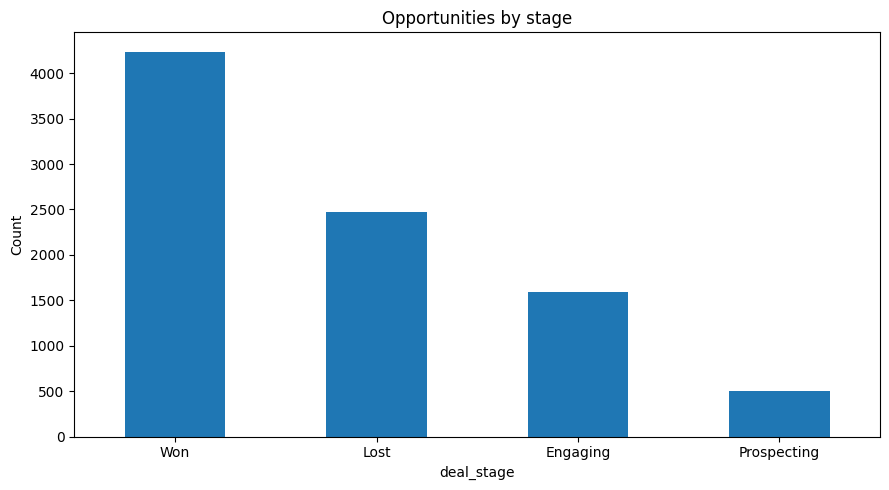

In [6]:
stage_counts.plot(kind='bar', title='Opportunities by stage')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Of decided deals, here's the Won/Lost split.

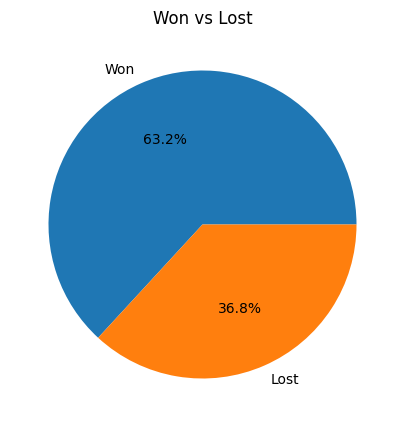

In [7]:
decided['deal_stage'].value_counts().plot(kind='pie', autopct='%1.1f%%', title='Won vs Lost')
plt.ylabel('')
plt.show()

Now the same split by month, to check if it's getting worse over time.

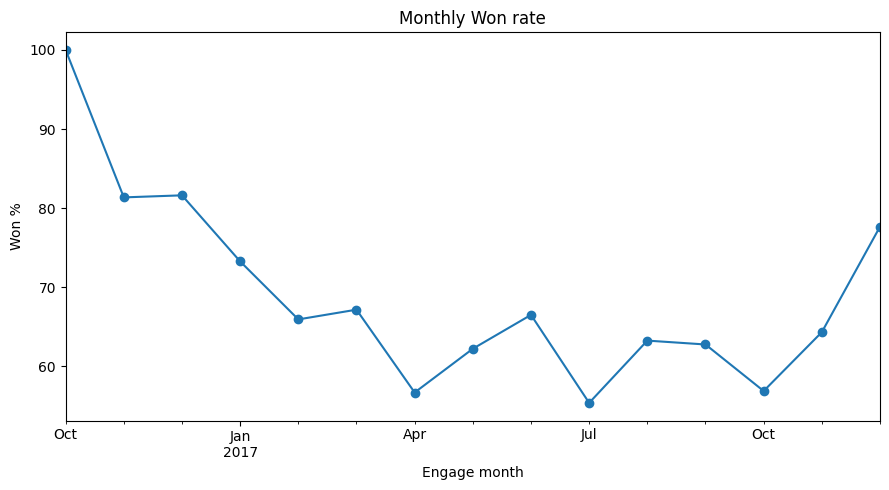

In [8]:
monthly = decided.groupby(decided['engage_date'].dt.to_period('M')).agg(
    won=('won', 'sum'),
    total=('won', 'count')
)
monthly['won_pct'] = (monthly['won'] / monthly['total'] * 100).round(2)
monthly['won_pct'].plot(marker='o', title='Monthly Won rate')
plt.ylabel('Won %')
plt.xlabel('Engage month')
plt.tight_layout()
plt.show()

The win rate starts high for deals engaged in late 2016 (above 80%), falls through early 2017, and from April through November stays between roughly 55% and 66%. December jumps to 78%, but on only 103 decided deals. The 2016 months hold few deals (7 in October, 102 in November), so read that early stretch with care.

In [10]:
decided['days_to_close'] = (decided['close_date'] - decided['engage_date']).dt.days
decided.groupby('deal_stage')['days_to_close'].mean().round(1)

deal_stage
Lost    41.5
Won     51.8
Name: days_to_close, dtype: float64

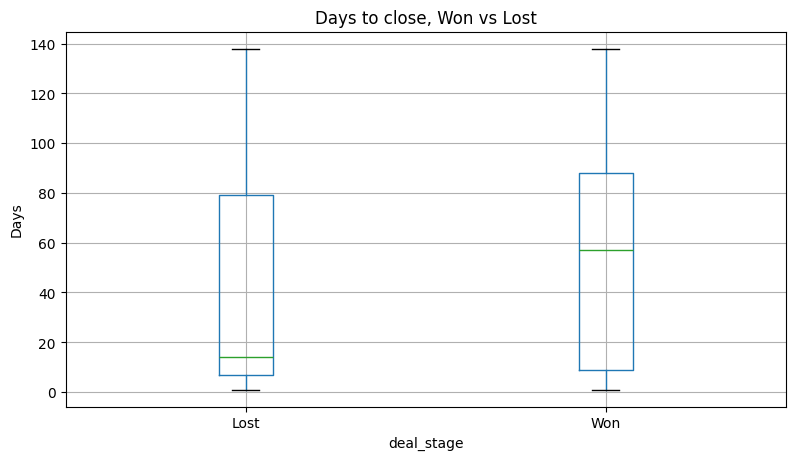

In [11]:
decided.boxplot(column='days_to_close', by='deal_stage')
plt.title('Days to close, Won vs Lost')
plt.suptitle('')
plt.ylabel('Days')
plt.show()

**Answer:** The stage counts show where deals sit today, not a narrowing funnel, so they can't show a leak between stages. What the data does show is the outcome: 37% of decided deals are lost, and those losses are concentrated in Outbound and Paid Ads (see Question 2). The win rate fell from above 80% for late-2016 engagements to a 55–66% band from April through November 2017. Won deals actually take longer to close than Lost ones (52 vs 41 days) — Lost deals get killed off fast, Won deals go through more back and forth.

## Question 2: Is the leak lead quality or rep execution?

In [12]:
by_source = decided.groupby('lead_source').agg(
    decided_deals=('won', 'count'),
    won=('won', 'sum')
)
by_source['won_pct'] = (by_source['won'] / by_source['decided_deals'] * 100).round(2)
by_source = by_source.sort_values('won_pct', ascending=False)
by_source

,decided_deals,won,won_pct
lead_source,,,
Referral,1739,1468,84.42
Partner,1078,840,77.92
Webinar,883,583,66.02
Organic Search,953,569,59.71
Outbound,1592,647,40.64
Paid Ads,466,131,28.11


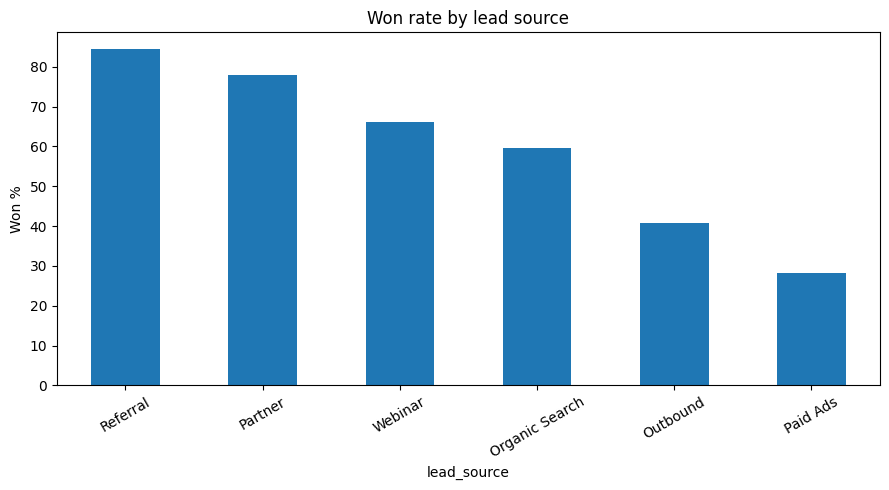

In [14]:
by_source['won_pct'].plot(kind='bar', title='Won rate by lead source')
plt.ylabel('Won %')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Lead score should track the outcome if it means anything. Checking that here.

In [15]:
df['outcome'] = np.where(df['deal_stage'].isin(['Prospecting', 'Engaging']), 'Open', df['deal_stage'])
score_by_outcome = df.groupby('outcome')['lead_score'].mean().round(1).sort_values(ascending=False)
score_by_outcome

outcome
Won     70.7
Open    59.2
Lost    53.1
Name: lead_score, dtype: float64

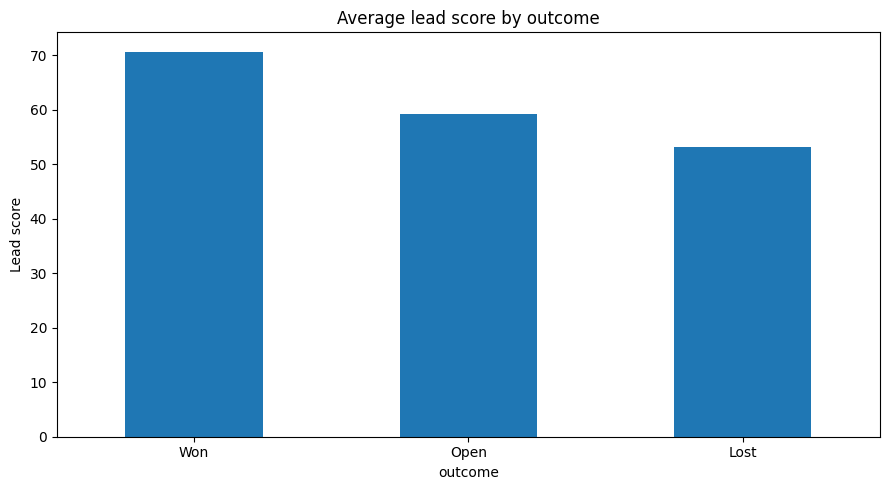

In [16]:
score_by_outcome.plot(kind='bar', title='Average lead score by outcome')
plt.ylabel('Lead score')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Cost per lead against win rate, by source.

In [17]:
cost_vs_win = decided.groupby('lead_source').agg(
    avg_cost_per_lead=('cost_per_lead_inr', 'mean'),
    won_pct=('won', lambda x: x.mean() * 100)
).round(2).sort_values('won_pct', ascending=False)
cost_vs_win

,avg_cost_per_lead,won_pct
lead_source,,
Referral,200.21,84.42
Partner,500.69,77.92
Webinar,1505.79,66.02
Organic Search,298.69,59.71
Outbound,800.95,40.64
Paid Ads,2200.57,28.11


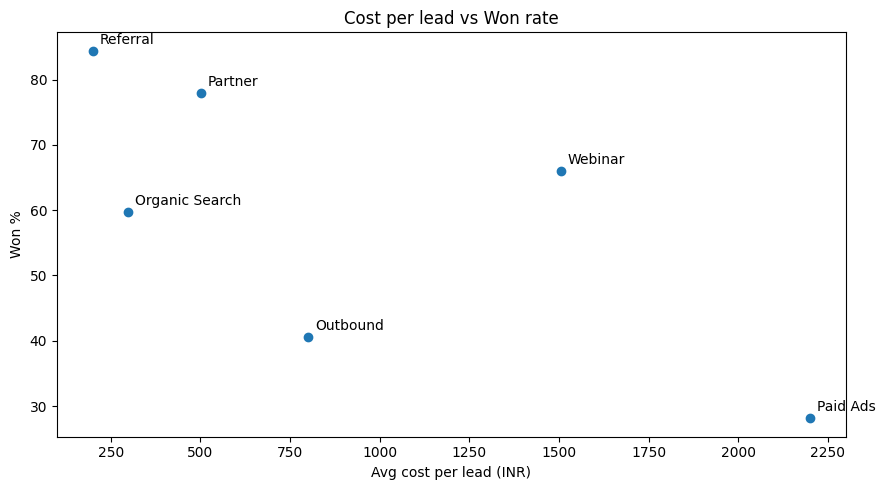

In [18]:
fig, ax = plt.subplots()
ax.scatter(cost_vs_win['avg_cost_per_lead'], cost_vs_win['won_pct'])
for source, row in cost_vs_win.iterrows():
    ax.annotate(source, (row['avg_cost_per_lead'], row['won_pct']), textcoords='offset points', xytext=(5, 5))
ax.set_xlabel('Avg cost per lead (INR)')
ax.set_ylabel('Won %')
ax.set_title('Cost per lead vs Won rate')
plt.tight_layout()
plt.show()

**Answer so far:** Lead quality clearly matters — Referral wins 65% of the time, Paid Ads wins 21%. Referral is also cheap and Paid Ads is expensive, so that channel is bad on both counts. But quality alone doesn't explain everything, which is why rep performance needs its own look.

## Question 3: Who are the real top performers vs. reps riding good leads?

Raw win rate rewards whoever gets the best leads. To find real skill, compare each rep's actual win rate against what their win rate *should* be given the quality of leads they were handed.

In [19]:
decided['lead_score_bucket'] = pd.qcut(decided['lead_score'], 5, labels=['Q1', 'Q2', 'Q3', 'Q4', 'Q5'])
bucket_rates = decided.groupby('lead_score_bucket', observed=True)['won'].mean()
bucket_rates

lead_score_bucket
Q1    0.302446
Q2    0.525019
Q3    0.665428
Q4    0.786567
Q5    0.880419
Name: won, dtype: float64

In [20]:
rows = []
for agent, group in decided.groupby('sales_agent'):
    n = len(group)
    expected_wins = group['lead_score_bucket'].map(bucket_rates).astype(float).sum()
    actual_wins = group['won'].sum()
    rows.append({
        'sales_agent': agent,
        'deals': n,
        'expected_win_rate_pct': round(expected_wins / n * 100, 2),
        'actual_win_rate_pct': round(actual_wins / n * 100, 2),
    })

quality_adjusted = pd.DataFrame(rows)
quality_adjusted['performance_gap'] = (quality_adjusted['actual_win_rate_pct']
                                        - quality_adjusted['expected_win_rate_pct']).round(2)
quality_adjusted = quality_adjusted.sort_values('performance_gap', ascending=False)
quality_adjusted

,sales_agent,deals,expected_win_rate_pct,actual_win_rate_pct,performance_gap
28,Wilburn Farren,79,60.48,69.62,9.14
19,Maureen Marcano,213,65.30,69.95,4.65
22,Reed Clapper,237,61.11,65.40,4.29
23,Rosalina Dieter,110,61.50,65.45,3.95
4,Corliss Cosme,229,62.11,65.50,3.39
1,Boris Faz,153,62.91,66.01,3.10
25,Versie Hillebrand,264,64.12,66.67,2.55
24,Rosie Papadopoulos,121,61.97,64.46,2.49
3,Cecily Lampkin,160,64.98,66.88,1.90
12,James Ascencio,206,63.72,65.53,1.81


Top 10 and bottom 10 by performance gap, side by side.

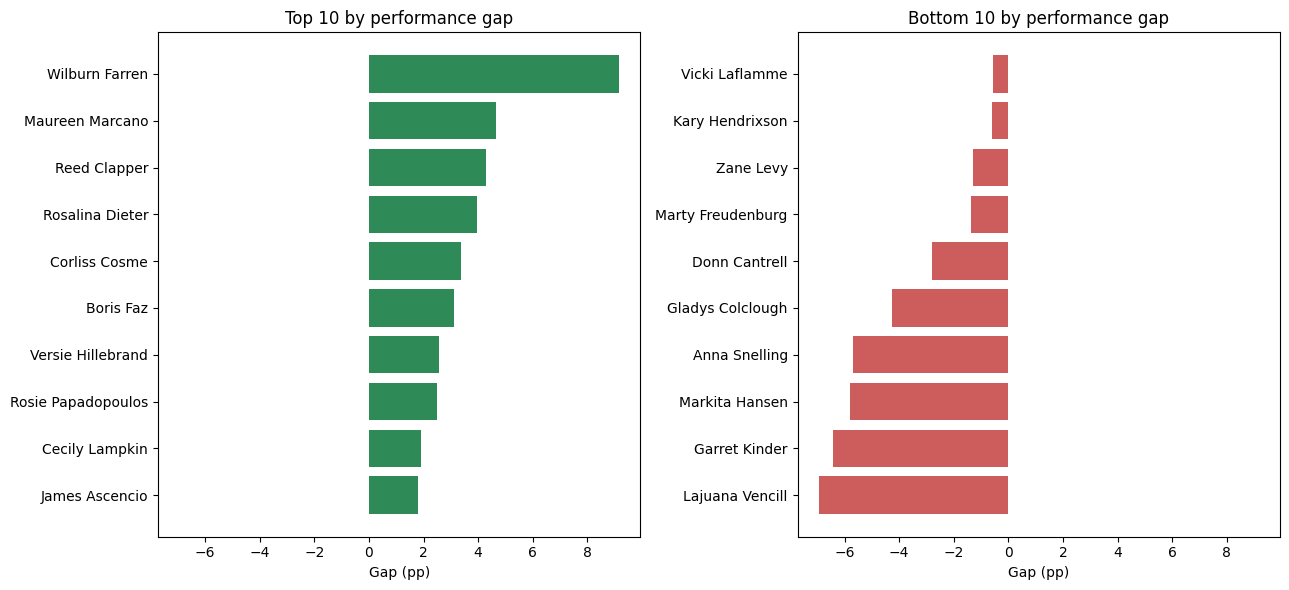

In [22]:
top10 = quality_adjusted.head(10)
bottom10 = quality_adjusted.tail(10)

fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharex=True)
axes[0].barh(top10['sales_agent'][::-1], top10['performance_gap'][::-1], color='seagreen')
axes[0].set_title('Top 10 by performance gap')
axes[0].set_xlabel('Gap (pp)')

axes[1].barh(bottom10['sales_agent'][::-1], bottom10['performance_gap'][::-1], color='indianred')
axes[1].set_title('Bottom 10 by performance gap')
axes[1].set_xlabel('Gap (pp)')

plt.tight_layout()
plt.show()

Expected vs actual win rate for everyone, in one view.

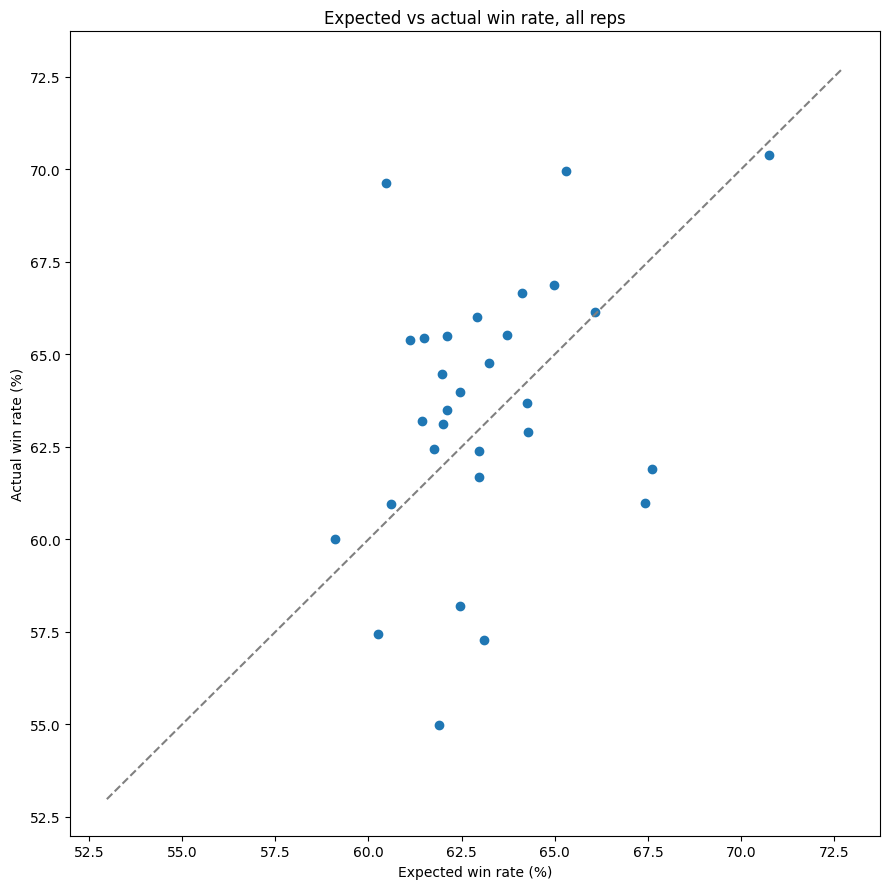

In [23]:
fig, ax = plt.subplots(figsize=(9, 9))
ax.scatter(quality_adjusted['expected_win_rate_pct'], quality_adjusted['actual_win_rate_pct'])
lims = [quality_adjusted[['expected_win_rate_pct', 'actual_win_rate_pct']].min().min() - 2,
        quality_adjusted[['expected_win_rate_pct', 'actual_win_rate_pct']].max().max() + 2]
ax.plot(lims, lims, linestyle='--', color='grey')
ax.set_xlabel('Expected win rate (%)')
ax.set_ylabel('Actual win rate (%)')
ax.set_title('Expected vs actual win rate, all reps')
plt.tight_layout()
plt.show()

Points above the dashed line are over-performing given their leads. Points below are under-performing.

In [24]:
manager_perf = decided.groupby('manager').agg(
    decided_deals=('won', 'count'),
    won_pct=('won', lambda x: round(x.mean() * 100, 2))
)
manager_perf['total_revenue'] = df[df['deal_stage'] == 'Won'].groupby('manager')['close_value'].sum()
manager_perf.sort_values('won_pct', ascending=False)

,decided_deals,won_pct,total_revenue
manager,,,
Cara Losch,745,64.43,1130049.0
Summer Sewald,1287,64.34,1964750.0
Celia Rouche,962,63.41,1603897.0
Dustin Brinkmann,1186,62.98,1094363.0
Melvin Marxen,1418,62.20,2251930.0
Rocco Neubert,1113,62.08,1960545.0


In [25]:
region_perf = decided.groupby('regional_office').agg(
    decided_deals=('won', 'count'),
    won_pct=('won', lambda x: round(x.mean() * 100, 2))
)
region_perf['total_revenue'] = df[df['deal_stage'] == 'Won'].groupby('regional_office')['close_value'].sum()
region_perf.sort_values('won_pct', ascending=False)

,decided_deals,won_pct,total_revenue
regional_office,,,
West,2249,63.94,3568647.0
East,1858,63.02,3090594.0
Central,2604,62.56,3346293.0


**Answer:** Wilburn Farren and Maureen Marcano are the strongest closers relative to the leads they got. Lajuana Vencill is the weakest, about 6.9 points below what her leads predict. Garret Kinder is close behind at 6.4 below — his numbers look fine on paper, but that's mostly the leads, not the selling. At the team level, Cara Losch's team wins at the best rate, Melvin Marxen's team brings in the most revenue on volume.

## Question 4: What's the ₹ impact of fixing this?

In [26]:
current_win_rate = decided['won'].mean()
total_decided = len(decided)
avg_deal_value = sp[sp['deal_stage'] == 'Won']['close_value'].mean()

print(f"Current win rate: {current_win_rate:.2%}")
print(f"Average deal value: ₹{avg_deal_value:,.2f}")

Current win rate: 63.15%
Average deal value: ₹2,360.91


Scenario 1: win rate goes up 5 points across every deal.

In [27]:
extra_wins_flat = total_decided * 0.05
extra_revenue_flat = extra_wins_flat * avg_deal_value
print(f"Extra wins: {extra_wins_flat:.0f}")
print(f"Extra revenue: ₹{extra_revenue_flat:,.0f}")

Extra wins: 336
Extra revenue: ₹792,203


Scenario 2: same 5-point gain, but only on one lead source at a time. Which source is worth the most?

In [28]:
source_impact = decided.groupby('lead_source').agg(
    deals=('won', 'count'),
    win_rate=('won', 'mean')
)
source_impact['extra_wins_5pp'] = source_impact['deals'] * 0.05
source_impact['extra_revenue_5pp'] = source_impact['extra_wins_5pp'] * avg_deal_value
source_impact = source_impact.sort_values('extra_revenue_5pp', ascending=False)
source_impact.round(2)

,deals,win_rate,extra_wins_5pp,extra_revenue_5pp
lead_source,,,,
Referral,1739,0.84,86.95,205281.07
Outbound,1592,0.41,79.60,187928.39
Partner,1078,0.78,53.90,127253.02
Organic Search,953,0.60,47.65,112497.33
Webinar,883,0.66,44.15,104234.15
Paid Ads,466,0.28,23.30,55009.19


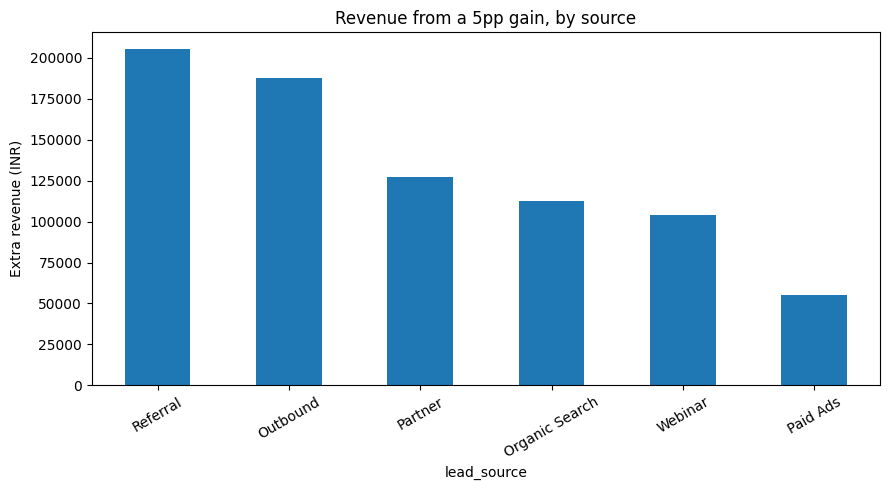

In [29]:
source_impact['extra_revenue_5pp'].plot(kind='bar', title='Revenue from a 5pp gain, by source')
plt.ylabel('Extra revenue (INR)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Referral wins here, not the worst-performing source. It has the best win rate and the most volume, so a 5pp gain on it is worth the most in absolute terms.

In [30]:
agent_perf = decided.groupby('sales_agent').agg(deals=('won', 'count'), wins=('won', 'sum'))
agent_perf['win_rate'] = agent_perf['wins'] / agent_perf['deals']
median_rate = agent_perf['win_rate'].median()

below_median = agent_perf[agent_perf['win_rate'] < median_rate].copy()
below_median['extra_wins'] = (median_rate - below_median['win_rate']) * below_median['deals']
below_median['extra_revenue'] = below_median['extra_wins'] * avg_deal_value

total_extra_revenue_reps = below_median['extra_revenue'].sum()
print(f"Reps below median: {len(below_median)} of {len(agent_perf)}")
print(f"Extra revenue if they reached the median: ₹{total_extra_revenue_reps:,.0f}")

Reps below median: 15 of 30
Extra revenue if they reached the median: ₹237,433


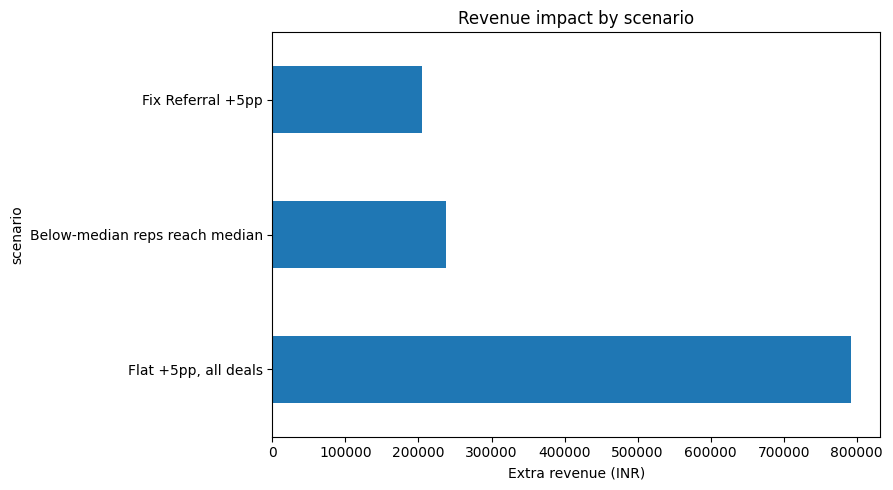

,scenario,extra_revenue_inr
0,"Flat +5pp, all deals",792203.146225
2,Below-median reps reach median,237432.848442
1,Fix Referral +5pp,205281.071567


In [31]:
comparison = pd.DataFrame({
    'scenario': ['Flat +5pp, all deals', 'Fix Referral +5pp', 'Below-median reps reach median'],
    'extra_revenue_inr': [
        extra_revenue_flat,
        source_impact.loc['Referral', 'extra_revenue_5pp'],
        total_extra_revenue_reps,
    ]
}).sort_values('extra_revenue_inr', ascending=False)

comparison.set_index('scenario')['extra_revenue_inr'].plot(kind='barh', title='Revenue impact by scenario')
plt.xlabel('Extra revenue (INR)')
plt.tight_layout()
plt.show()

comparison

Exporting this for the Power BI dashboard, same as the other summary tables below.

In [32]:
import os
os.makedirs('powerbi_exports', exist_ok=True)
comparison.to_csv('powerbi_exports/revenue_scenarios.csv', index=False)

**Answer:** A flat 5-point gain across the board is worth about ₹7.9 lakh. Fixing the single best lead source (Referral) is worth about ₹2 lakh. Getting below-median reps up to the median is worth about ₹2.4 lakh but is the hardest of the three to actually do, since it means improving people rather than reallocating leads.

## Summary

1. 37% of decided deals are lost, mostly from Outbound and Paid Ads leads. The win rate dropped from above 80% in late 2016 to a 55–66% band from April through November 2017.
2. Lead quality drives a lot of the outcome, but not all of it — rep skill is real and separate.
3. Wilburn Farren and Maureen Marcano over-perform their lead quality. Lajuana Vencill and Garret Kinder under-perform theirs.
4. A 5-point improvement is worth roughly ₹2–8 lakh depending on where it comes from. Referral is the best single lever to pull.